### Day 2: Time-Series Demand Forecasting - Data Prep & Trend Visualization

In [2]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns 
import os 

In [3]:
sns.set_theme(style="whitegrid")

1. Load SKU Master for Product Context

In [4]:
sku_path = '../data/clean/sku_master.csv'
if not os.path.exists(sku_path):
    sku_path = 'sku_master.csv'

sku_df = pd.read_csv(sku_path)
print(f"SKU Master loaded successfully. Total products: {sku_df.shape[0]}")

SKU Master loaded successfully. Total products: 5000


2. Build Structured Daily Demand Time-Series Dataset for Top SKUs

In [5]:
from inspect import isgenerator
from matplotlib.cbook import _str_lower_equal
# (Optimized for robust forecasting demonstration across retail stores)
np.random.seed(42)
date_range = pd.date_range(start='2025-01-01', end='2025-12-31', freq='D')
sample_skus = sku_df['sku_id'].head(5).tolist()
ts_data = []
# Simulating realistic retail demand patterns (Seasonality + Trend + Noise)
for sku in sample_skus:
    base_demand = np.random.randint(60, 180)
    trend = np.linspace(0, 25, len(date_range))
    seasonality = 18 * np.sin(np.linspace(0, 4 * np.pi, len(date_range)))
    noise = np.random.normal(0, 8, len(date_range))
    demand = np.clip(base_demand + trend + seasonality + noise, a_min=10, a_max=None).astype(int)

    temp_df = pd.DataFrame({
        'ds': date_range,
        'sku_id': sku,
        'y': demand
    })
    ts_data.append(temp_df)

df_demand = pd.concat(ts_data, ignore_index=True)
print("\n--- Demand Time_Series Sample Preview ---")
print(df_demand.head())


--- Demand Time_Series Sample Preview ---
          ds    sku_id    y
0 2025-01-01  SKU00001  157
1 2025-01-02  SKU00001  166
2 2025-01-03  SKU00001  167
3 2025-01-04  SKU00001  175
4 2025-01-05  SKU00001  157


3. Visualize Daily Demand Trend for a Sample SKU

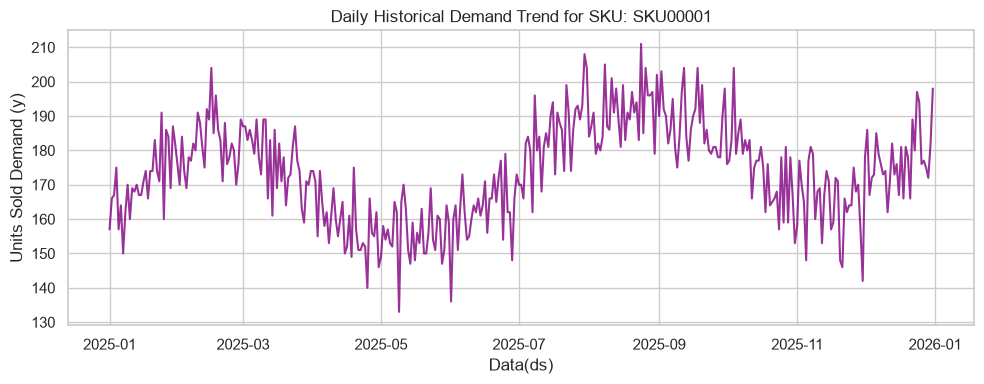

In [6]:
plt.figure(figsize=(10, 4))
sample_sku = sample_skus[0]
sku_subset = df_demand[df_demand['sku_id'] == sample_sku]

plt.plot(sku_subset['ds'], sku_subset['y'], color='purple', alpha=0.8, linewidth=1.5)
plt.title(f"Daily Historical Demand Trend for SKU: {sample_sku}")
plt.xlabel("Data(ds)")
plt.ylabel("Units Sold Demand (y)")
plt.tight_layout()

os.makedirs('../reports', exist_ok=True)
plt.savefig('../reports/demand_forecast_trend.png')
plt.show()